# 👕 Lesson 09 · Project 2 · Image Classification

*“Anyone can train a model. A professional compares models fairly, studies the errors, and reports honestly.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~150 min | 🟡 Intermediate | Day 7–8 | Lessons 05–08 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Run a **fair model comparison** (ANN vs CNN vs improved CNN) using the validation set only
- Use **data augmentation** correctly, and know when a transformation is *label-preserving*
- Add **batch normalisation** and **dropout** to a CNN (previewing Lesson 14)
- Report **top-k accuracy, per-class F1** and the **most confused class pairs**
- Choose a model with validation data, then touch the **test set exactly once**

## 🗺 Roadmap
1. Project brief
2. Explore Fashion-MNIST
3. Split & preprocess
4. Experiment 1: ANN baseline
5. Experiment 2: a CNN
6. Experiment 3: BatchNorm + Dropout
7. Experiment 4: data augmentation
8. Choose the winner, test once
9. Error analysis
10. Report & stretch goals
11. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn, torch.nn.functional as F
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📋 1. Project brief

> **Client.** A *mitumba* (second-hand clothing) market trader wants a phone app that sorts photographed items into categories to price and shelve them quickly.
> **Your job.** Build the image classifier at its heart: 10 clothing categories from 28×28 grayscale pictures.

| | |
|:--|:--|
| **Data** | **Fashion-MNIST** (Zalando): 10 classes; T-shirt, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot. We ship 15,000 train + 5,000 test images. |
| **Why harder than digits?** Classes like *Shirt / T-shirt / Pullover / Coat* look alike; a model must see texture & shape, not just a stroke. |
| **Success criteria** | ≥ **88 %** test accuracy (stretch: 90 %) · a fair, logged comparison of ≥ 3 models · an error analysis that says *which* classes fail and why |
| **Deliverable** | This notebook + the report table in Section 10 |

**New this time: experiment discipline.** We'll run a *ladder* of experiments, change **one thing at a time**, log everything, and decide using validation accuracy alone.

---
## 🔭 2. Explore

train pool: (15000, 28, 28) | test: (5000, 28, 28) | class counts: [1483 1549 1451 1523 1447 1485 1536 1489 1522 1515]


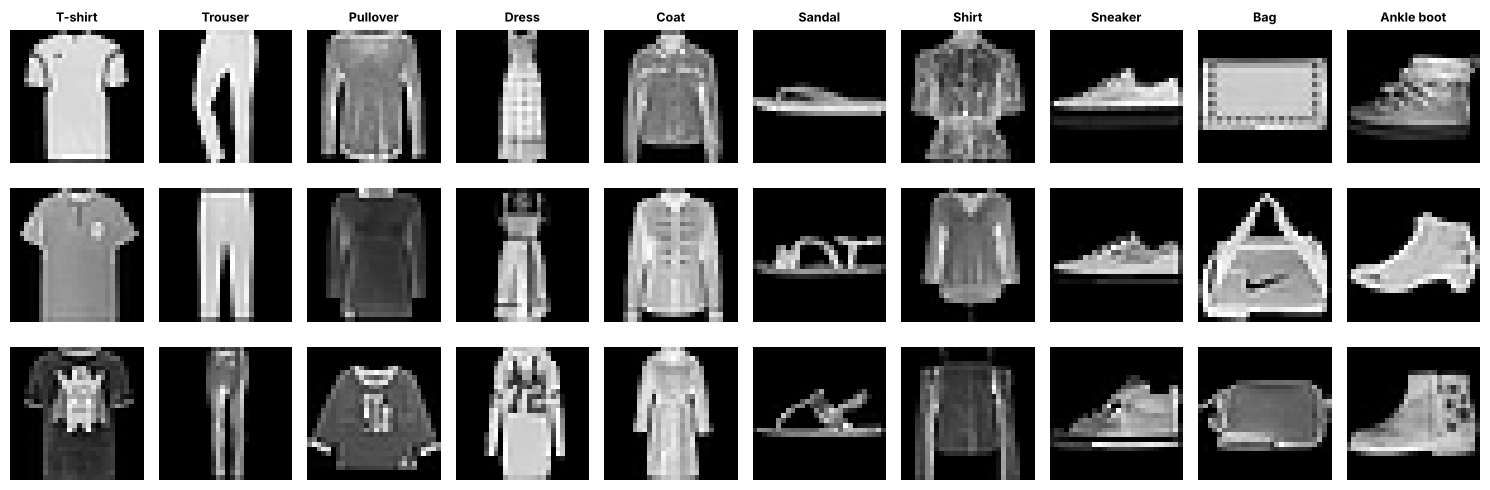

In [2]:
x_all, y_all, x_test, y_test = dl.load_fashion()
names = dl.FASHION_CLASSES
print("train pool:", x_all.shape, "| test:", x_test.shape, "| class counts:", np.bincount(y_all))
fig, axes = plt.subplots(3, 10, figsize=(15, 5.2))
for c in range(10):
    for r, idx in enumerate(np.where(y_all == c)[0][:3]):
        axes[r, c].imshow(x_all[idx], cmap="gray"); axes[r, c].axis("off")
    axes[0, c].set_title(names[c], fontsize=9)
plt.tight_layout(); plt.show()

🤔 **Pause and think.** Before training anything: which *pairs* of classes do you expect to be confused? Write down 3 guesses, then check them in Section 9.

<details><summary>Click to reveal the answer</summary>

Likely: **Shirt ↔ T-shirt**, **Pullover ↔ Coat**, **Shirt ↔ Pullover/Coat**, maybe **Sneaker ↔ Ankle boot** and **Sandal ↔ Sneaker**. Trousers, bags and footwear-vs-clothing should be easy.

</details>

---
## ✂️ 3. Split & preprocess

In [3]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(y_all)); val_idx, tr_idx = perm[:3000], perm[3000:]
x_tr, y_tr, x_val, y_val = x_all[tr_idx], y_all[tr_idx], x_all[val_idx], y_all[val_idx]
mu, sd = x_tr.mean(), x_tr.std()                        # statistics from TRAIN only
prep = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32)[:, None]       # → (N, 1, 28, 28)
Xtr, Xval, Xte = prep(x_tr), prep(x_val), prep(x_test)
Ytr, Yval, Yte = (torch.tensor(a) for a in (y_tr, y_val, y_test))
bg = float((0 - mu) / sd)                               # the normalised value of a black background pixel
train_dl = DataLoader(TensorDataset(Xtr, Ytr), batch_size=64, shuffle=True)
val_dl = DataLoader(TensorDataset(Xval, Yval), batch_size=1000)
print(f"train {len(Ytr):,} | val {len(Yval):,} | test {len(Yte):,} (locked) | {len(train_dl)} batches/epoch")

results = []                                            # our experiment log
def run_experiment(name, model, loader=train_dl, epochs=10, lr=1e-3, seed=0):
    dl.set_seed(seed)
    h = dl.fit(model, loader, val_dl, nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=lr), epochs=epochs, device=cpu, verbose=False)
    results.append({"experiment": name, "params": dl.count_params(model), "best val acc": max(h["val_acc"]),
                    "final val acc": h["val_acc"][-1], "final train acc": h["train_acc"][-1], "seconds": round(h["seconds"])})
    print(f"{name:34s} val acc {h['val_acc'][-1]:.3f} | train acc {h['train_acc'][-1]:.3f} | {h['seconds']:.0f}s")
    return h

train 12,000 | val 3,000 | test 5,000 (locked) | 188 batches/epoch


---
## 🧪 4. Experiment 1: the ANN baseline

In [4]:
def make_ann():
    dl.set_seed(0)
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
ann = make_ann(); h_ann = run_experiment("1. ANN 784-256-128-10", ann)

1. ANN 784-256-128-10              val acc 0.846 | train acc 0.920 | 5s


---
## 🧪 5. Experiment 2: a plain CNN

In [5]:
def make_cnn():
    dl.set_seed(0)
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),        # 16×14×14
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # 32×7×7
        nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))
cnn = make_cnn(); h_cnn = run_experiment("2. CNN (2 conv blocks)", cnn)

2. CNN (2 conv blocks)             val acc 0.870 | train acc 0.922 | 32s


---
## 🧪 6. Experiment 3: add BatchNorm & Dropout

Two ingredients (explored fully in Lesson 14):

* **BatchNorm2d**: after each conv, re-centre and re-scale activations to mean 0 / std 1 *per batch*, then let the network learn a scale and shift. Effect: much more stable and faster training; tolerates higher learning rates.
* **Dropout(p)**: during training, randomly zero a fraction `p` of activations. Forces the network not to rely on any single neuron → **less overfitting**. (It switches off automatically under `model.eval()`.)

In [6]:
def make_cnn_bn(p=0.3):
    dl.set_seed(0)
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Dropout(p), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 10))
cnn_bn = make_cnn_bn(); h_bn = run_experiment("3. CNN + BatchNorm + Dropout", cnn_bn)

3. CNN + BatchNorm + Dropout       val acc 0.886 | train acc 0.888 | 41s


---
## 🧪 7. Experiment 4: data augmentation

**Data augmentation** makes *new* training examples by transforming existing ones in ways that **do not change the label**. The network sees each image slightly differently every epoch: a cheap way to get "more data" and teach invariances.

> ⚠️ **The golden rule: the transformation must preserve the label.** Flipping a T-shirt left↔right is still a T-shirt ✅. Flipping the digit **6** or the letter **b** is *not* the same thing ❌. Rotating a leaf photo is fine (Lesson 10); rotating a "6" by 180° gives a "9".

We'll use (a) random **horizontal flips** and (b) random **shifts** of up to 1 px. Augment **only the training data**: never validation or test.

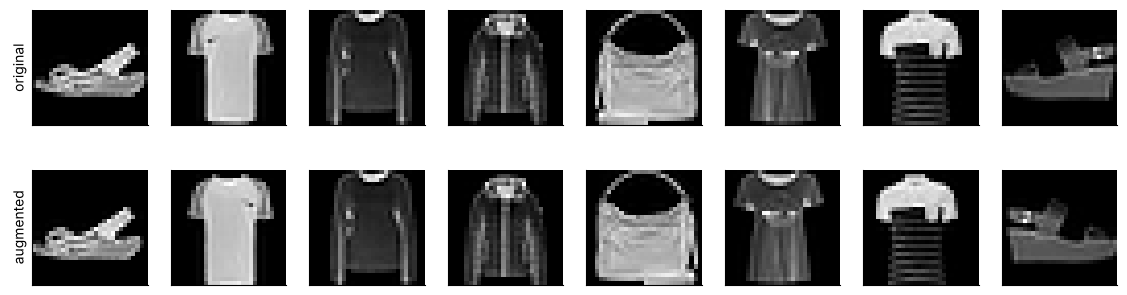

4. CNN + BN + light dropout + augmentation val acc 0.885 | train acc 0.888 | 52s


In [7]:
def augment(xb, max_shift=1):
    B = len(xb)
    flip = torch.rand(B) < 0.5
    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)                  # random horizontal flip
    padded = F.pad(xb, (max_shift,) * 4, value=bg)                                # pad with background colour
    dx, dy = torch.randint(0, 2 * max_shift + 1, (B,)), torch.randint(0, 2 * max_shift + 1, (B,))
    out = torch.empty_like(xb)
    for i in range(B):                                                            # random crop back to 28×28
        out[i] = padded[i, :, dy[i]:dy[i] + 28, dx[i]:dx[i] + 28]
    return out

class AugLoader:
    """Wraps a DataLoader and augments each training batch on the fly."""
    def __init__(self, loader): self.loader = loader
    def __len__(self): return len(self.loader)
    def __iter__(self):
        for xb, yb in self.loader: yield augment(xb), yb

xb, _ = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for i in range(8):
    axes[0, i].imshow(xb[i, 0], cmap="gray"); axes[1, i].imshow(augment(xb)[i, 0], cmap="gray")
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("augmented")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.show()
cnn_aug = make_cnn_bn(p=0.1)          # with augmentation already regularising, we can dial dropout down
h_aug = run_experiment("4. CNN + BN + light dropout + augmentation", cnn_aug, loader=AugLoader(train_dl), epochs=12, lr=2e-3)

---
## 📊 8. Compare fairly: choose the winner - test ONCE

,params,best val acc,final val acc,final train acc,seconds,overfit gap (train−val)
experiment,,,,,,
1. ANN 784-256-128-10,235146,0.860,0.846,0.920,5,0.075
2. CNN (2 conv blocks),105866,0.880,0.870,0.922,32,0.052
3. CNN + BatchNorm + Dropout,105962,0.886,0.886,0.888,41,0.002
4. CNN + BN + light dropout + augmentation,105962,0.893,0.885,0.888,52,0.003


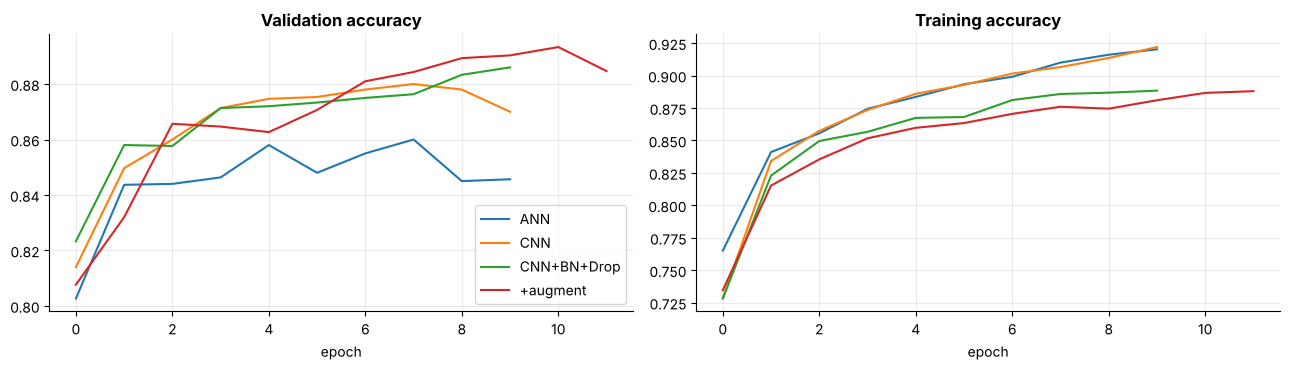

In [8]:
df = pd.DataFrame(results).set_index("experiment")
df["overfit gap (train−val)"] = df["final train acc"] - df["final val acc"]
display(df.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, h in [("ANN", h_ann), ("CNN", h_cnn), ("CNN+BN+Drop", h_bn), ("+augment", h_aug)]:
    ax[0].plot(h["val_acc"], label=name); ax[1].plot(h["train_acc"], label=name)
ax[0].set(title="Validation accuracy", xlabel="epoch"); ax[1].set(title="Training accuracy", xlabel="epoch"); ax[0].legend()
plt.tight_layout(); plt.show()

**How to read the table.** Look at *validation* accuracy to rank models, and at the **overfit gap** to see how much each model memorised. Typically: CNN > ANN; BN + dropout shrinks the gap; augmentation shrinks it further and often adds a little accuracy (especially with longer training).

> 📏 **Manage your expectations.** All the CNN variants land close together (≈ 87–89 %). That's normal: we're using just **12,000** training images and a deliberately tiny, CPU-friendly network. Real gains from *stronger regularisation* show up when the model is bigger or data scarcer; on the full 60,000-image dataset this same CNN reaches ≈ 91–92 %. **Differences of 0.3 % on a 3,000-image validation set are within noise** (one standard error ≈ 0.6 %): don't over-interpret them.

We now pick the model with the best **validation** accuracy and evaluate it on the test set. **Once.**

In [9]:
candidates = {"ANN": ann, "CNN": cnn, "CNN+BN+Drop": cnn_bn, "CNN+aug": cnn_aug}
best_name = max(candidates, key=lambda n: dl.evaluate(candidates[n], val_dl, nn.CrossEntropyLoss(), cpu)[1])
final = candidates[best_name]
probs = dl.predict_proba(final, Xte, device=cpu)
preds = probs.argmax(1).numpy()
print(f"🏆 Selected by validation accuracy: {best_name}")
print(f"🎯 TEST ACCURACY: {(preds == y_test).mean():.2%}")

🏆 Selected by validation accuracy: CNN+BN+Drop
🎯 TEST ACCURACY: 88.94%


---
## 🔬 9. Error analysis

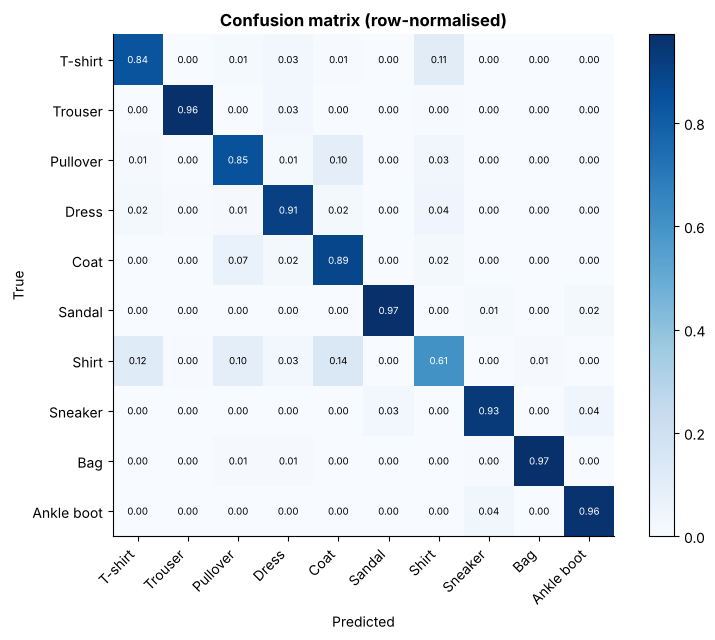

              precision    recall  f1-score   support

     T-shirt      0.849     0.838     0.843       482
     Trouser      0.988     0.965     0.976       509
    Pullover      0.810     0.845     0.827       498
       Dress      0.878     0.909     0.893       497
        Coat      0.772     0.886     0.825       498
      Sandal      0.962     0.972     0.967       493
       Shirt      0.744     0.605     0.667       489
     Sneaker      0.943     0.931     0.937       495
         Bag      0.986     0.972     0.979       492
  Ankle boot      0.951     0.958     0.954       547

    accuracy                          0.889      5000
   macro avg      0.888     0.888     0.887      5000
weighted avg      0.889     0.889     0.888      5000



In [10]:
cm = dl.plot_confusion(y_test, preds, class_names=names, normalize=True, figsize=(8, 6.5))
from sklearn.metrics import classification_report
print(classification_report(y_test, preds, target_names=names, digits=3))

Most confused pairs (true → predicted : count)
  Shirt      → Coat      : 68
  Shirt      → T-shirt   : 57
  T-shirt    → Shirt     : 52
  Shirt      → Pullover  : 48
  Pullover   → Coat      : 48

top-1 accuracy 88.94%  |  top-3 accuracy 99.02%


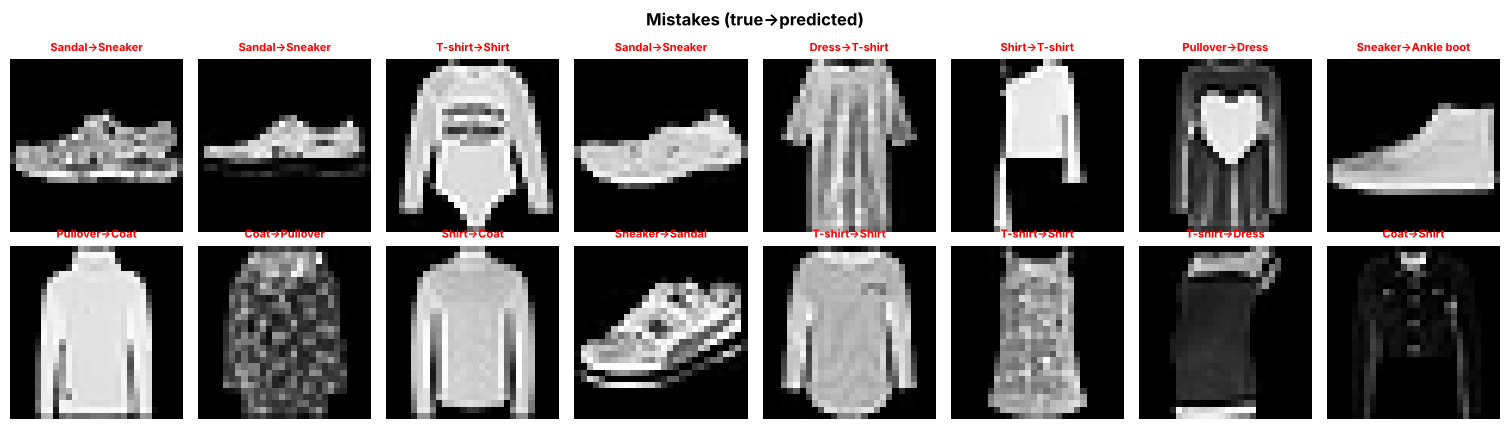

In [11]:
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], names[i], names[j]) for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
print("Most confused pairs (true → predicted : count)")
for n, a, b in pairs: print(f"  {a:10s} → {b:10s}: {n}")
top3 = np.mean([y_test[i] in np.argsort(-probs[i].numpy())[:3] for i in range(len(y_test))])
print(f"\ntop-1 accuracy {np.mean(preds == y_test):.2%}  |  top-3 accuracy {top3:.2%}")
wrong = np.where(preds != y_test)[0]
dl.show_images(x_test[wrong[:16]], y_test[wrong[:16]], class_names=names, preds=preds[wrong[:16]], n=16, ncols=8, figscale=1.9, title="Mistakes (true→predicted)")

> 🇰🇪 **In the field**: If *Shirt ↔ T-shirt* confusion dominates, a pricing app might not care (similar value!). If *Sneaker ↔ Sandal* confusion dominates, it might (different prices). **Error analysis connects model mistakes to business cost**: the metric that matters is the one tied to the user's decisions.

---
## 📝 10. Report & stretch goals

| Item | Your entry |
|:--|:--|
| Problem & success criterion | |
| Data & split | 12,000 / 3,000 / 5,000; train-only normalisation |
| Experiment log (paste the table above) | |
| Chosen model & why | selected by **validation** accuracy |
| **Test accuracy (once)** | |
| Per-class weaknesses | worst F1 classes: |
| Top confused pairs & hypothesis why | |
| Limitations | 28×28 grayscale, studio-style images; real phone photos differ (distribution shift) |
| Next steps | |

### 🚀 Stretch goals
1. Add a third conv block (64 filters): does validation accuracy improve? Does the gap grow?
2. Replace `Flatten→Linear` by **global average pooling** (`nn.AdaptiveAvgPool2d(1)`): fewer parameters, similar accuracy?
3. Try a learning-rate schedule (`CosineAnnealingLR`): preview of Lesson 14.
4. Implement **label smoothing** (`nn.CrossEntropyLoss(label_smoothing=0.1)`) and compare calibration.
5. **Ensembling:** average the probabilities of two differently-initialised CNNs. How much does accuracy rise?

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 9.1: Flip a batch  &nbsp; `⭐`

Write `hflip_batch(x, mask)`: `x` has shape `(B, C, H, W)`, `mask` is a boolean tensor of shape `(B,)`. Return a tensor where the images with `mask == True` are flipped left↔right (width axis) and the others are unchanged. No Python loop.

<details><summary>💡 Hint 1</summary>

`x.flip(3)` flips the last (width) axis for every image.

</details>

<details><summary>💡 Hint 2</summary>

`torch.where(cond, a, b)` selects element-wise; `cond` must broadcast to `x`: use `mask[:, None, None, None]`.

</details>


In [ ]:
def hflip_batch(x, mask):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = torch.arange(2 * 1 * 2 * 3, dtype=torch.float32).reshape(2, 1, 2, 3)
out = hflip_batch(x, torch.tensor([True, False]))
dl.check("image 0 flipped", out is not None and torch.equal(out[0], x[0].flip(2)))
dl.check("image 1 untouched", out is not None and torch.equal(out[1], x[1]))

---
### 🧩 Problem 9.2: Shift a batch (per-image offsets)  &nbsp; `⭐⭐`

Write `shift_batch(x, dxs, dys, pad_value=0.0)`. `x` is `(B, C, H, W)`; `dxs`, `dys` are integer lists of length `B` (positive = move right / down; at most ±`m` for some small `m`).
Return the shifted batch, with vacated pixels filled by `pad_value` and nothing wrapped around.

<details><summary>💡 Hint 1</summary>

Pad first: `F.pad(x, (m, m, m, m), value=pad_value)` with `m = max(abs(...))`.

</details>

<details><summary>💡 Hint 2</summary>

For image `i`, crop `padded[i, :, m - dy : m - dy + H, m - dx : m - dx + W]`.

</details>

<details><summary>💡 Hint 3</summary>

Moving the content **right by dx** means the crop window moves **left** by dx in the padded image.

</details>


In [ ]:
def shift_batch(x, dxs, dys, pad_value=0.0):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = torch.arange(1, 10, dtype=torch.float32).reshape(1, 1, 3, 3)       # [[1 2 3],[4 5 6],[7 8 9]]
r = shift_batch(torch.cat([x, x]), [1, 0], [0, -1])
dl.check("image 0 moved right by 1", r is not None and torch.equal(r[0, 0], torch.tensor([[0., 1, 2], [0, 4, 5], [0, 7, 8]])))
dl.check("image 1 moved up by 1", r is not None and torch.equal(r[1, 0], torch.tensor([[4., 5, 6], [7, 8, 9], [0, 0, 0]])))
dl.check("pad_value is honoured", torch.equal(shift_batch(x, [1], [0], pad_value=-1.0)[0, 0, :, 0], torch.tensor([-1., -1, -1])))

---
### 🧩 Problem 9.3: Top-k accuracy  &nbsp; `⭐`

Write `topk_accuracy(probs, y, k)`: the fraction of examples whose true label is among the `k` highest-probability classes. `probs` is an `(N, C)` NumPy array.

<details><summary>💡 Hint 1</summary>

`np.argsort(-probs, axis=1)[:, :k]` gives the indices of the k best classes per row.

</details>

<details><summary>💡 Hint 2</summary>

Check membership: `(top == y[:, None]).any(axis=1).mean()`.

</details>


In [ ]:
def topk_accuracy(probs, y, k=3):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
p = np.array([[.5, .3, .2], [.1, .2, .7], [.2, .5, .3]]); y = np.array([0, 1, 0])
dl.check("top-1 = 1/3", topk_accuracy(p, y, 1) is not None and np.isclose(topk_accuracy(p, y, 1), 1/3))
dl.check("top-2 = 2/3", np.isclose(topk_accuracy(p, y, 2) or 0, 2/3))
dl.check("top-3 = 1", np.isclose(topk_accuracy(p, y, 3) or 0, 1.0))

---
### 🧩 Problem 9.4: F1 scores from a confusion matrix  &nbsp; `⭐⭐`

Given a confusion matrix `cm` (rows = true, columns = predicted), write `f1_scores(cm)` returning an array with the **F1 of every class**:
precision = TP / (column sum), recall = TP / (row sum), F1 = 2PR/(P+R). Use 0 when P+R = 0.

<details><summary>💡 Hint 1</summary>

`tp = np.diag(cm)`; precision = `tp / cm.sum(0)`; recall = `tp / cm.sum(1)`.

</details>

<details><summary>💡 Hint 2</summary>

Guard division by zero with `np.where(denominator == 0, 0, ...)` or add a tiny epsilon.

</details>


In [ ]:
def f1_scores(cm):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
cm = np.array([[8, 2, 0], [1, 9, 0], [0, 0, 0]])
f = f1_scores(cm)
dl.check("class 0: P=8/9, R=0.8 → F1≈0.842", f is not None and np.isclose(f[0], 2 * (8/9) * .8 / (8/9 + .8)))
dl.check("class 1: P=9/11, R=0.9", f is not None and np.isclose(f[1], 2 * (9/11) * .9 / (9/11 + .9)))
dl.check("empty class gets 0, not NaN", f is not None and f[2] == 0)

---
### 🧩 Problem 9.5: Most confused pairs  &nbsp; `⭐⭐`

Write `confused_pairs(cm, names, top=3)` returning a list of `(true_name, predicted_name, count)` for the `top` largest **off-diagonal** entries, sorted by count descending.

<details><summary>💡 Hint 1</summary>

Copy `cm` and zero its diagonal with `np.fill_diagonal`.

</details>

<details><summary>💡 Hint 2</summary>

Build a list of `(count, i, j)` for all `i != j`, sort descending, slice `[:top]`.

</details>


In [ ]:
def confused_pairs(cm, names, top=3):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
cm = np.array([[50, 7, 1], [2, 40, 9], [0, 3, 30]])
r = confused_pairs(cm, ["shirt", "coat", "bag"], top=2)
dl.check("top pair is coat→bag (9)", r is not None and r[0] == ("coat", "bag", 9))
dl.check("second pair is shirt→coat (7)", r is not None and r[1] == ("shirt", "coat", 7))

---
## 🏁 Key takeaways
- ✅ Run a **ladder of experiments**: change one thing at a time, log params / val accuracy / overfit gap.
- ✅ **CNN > ANN** on images; **BatchNorm + Dropout** stabilise and regularise; **augmentation** teaches invariances.
- ✅ Augmentation must **preserve the label** (flip a shirt ✅, flip a '6' ❌) and applies to **training data only**.
- ✅ Choose the model with **validation** data; report the **test** score once.
- ✅ Go beyond accuracy: **top-k, per-class F1, confusion pairs**: and relate mistakes to real-world cost.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why do we augment the training set but not the validation set?

<details><summary>Answer</summary>

Validation must estimate performance on *real, untouched* data. Augmenting it would measure performance on artificial variants and make comparisons inconsistent.

</details>

**Q2.** A CNN has 99 % training and 90 % validation accuracy. Name three remedies.

<details><summary>Answer</summary>

More data / stronger augmentation; dropout and weight decay; a smaller model; early stopping.

</details>

**Q3.** Which of these augmentations is label-preserving for *leaf disease* images: horizontal flip, 90° rotation, strong colour shift toward yellow?

<details><summary>Answer</summary>

Flip ✅ and rotation ✅ (a leaf has no canonical orientation). A strong yellow shift ❌: it could make a healthy leaf look like *maize streak*, changing the true label.

</details>

**Q4.** Why report top-3 accuracy as well as top-1?

<details><summary>Answer</summary>

When the app can show several suggestions (or a human picks), top-k tells you how often the right answer is among them even when it isn't first.

</details>

---
## 📚 Go deeper (optional)
- Xiao, Rasul & Vollgraf (2017): *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*
- Shorten & Khoshgoftaar (2019): *A survey on image data augmentation for deep learning*
- Ioffe & Szegedy (2015) (*Batch Normalization*; Srivastava et al. (2014)) *Dropout*

---
⬅️ Previous: [08 · Convolutional Neural Networks](08_convolutional_networks.ipynb) &nbsp;|&nbsp; Next: [10 · Project 3 · Crop Disease Classification](10_project3_crop_disease.ipynb) ➡️